11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Image shape: (28, 28)
Label: 5


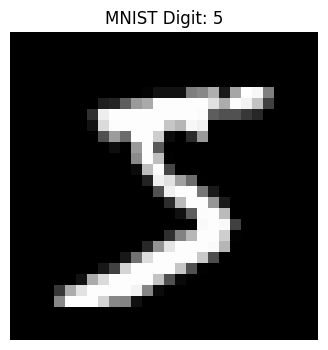

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

# Select one image
img = X_train[0]

print("Image shape:", img.shape)
print("Label:", y_train[0])

# Display
plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray")
plt.title(f"MNIST Digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Resize MNIST image from 28x28 to 32x32
img_32 = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA)

print("Resized image shape:", img_32.shape)

# Initial patch size
patch_size = 8

# Calculate variance for every 8x8 patch
complexity_map = []

for i in range(0, 32, patch_size):
    row = []

    for j in range(0, 32, patch_size):
        patch = img_32[i:i+patch_size, j:j+patch_size]

        # Variance = complexity measure
        variance = np.var(patch)

        row.append(variance)

    complexity_map.append(row)

complexity_map = np.array(complexity_map)

print("Complexity map shape:", complexity_map.shape)
print("\nComplexity values:")
print(complexity_map)

Resized image shape: (32, 32)
Complexity map shape: (4, 4)

Complexity values:
[[    0.          2072.02905273  6951.46777344  3703.82592773]
 [    0.         11145.09277344  7137.14746094    75.02734375]
 [    0.          2534.625       9340.33984375     0.        ]
 [ 3057.55249023 10921.75952148  1944.61499023     0.        ]]


In [ ]:
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio
from skimage.metrics import structural_similarity

def reconstruct_fixed(image, patch_size):
    """
    Reconstruct image by replacing every fixed-size
    patch with its mean intensity.
    """
    reconstructed = np.zeros_like(image, dtype=np.float32)

    for y in range(0, image.shape[0], patch_size):
        for x in range(0, image.shape[1], patch_size):

            patch = image[
                y:y+patch_size,
                x:x+patch_size
            ]

            mean_value = np.mean(patch)

            reconstructed[
                y:y+patch_size,
                x:x+patch_size
            ] = mean_value

    return np.clip(reconstructed, 0, 255).astype(np.uint8)


def calculate_metrics(original, reconstructed):

    mse = mean_squared_error(original, reconstructed)

    psnr = peak_signal_noise_ratio(
        original,
        reconstructed,
        data_range=255
    )

    ssim = structural_similarity(
        original,
        reconstructed,
        data_range=255
    )

    return mse, psnr, ssim


# Fixed patch experiments
fixed_results = {}

for size in [8, 4, 2]:

    reconstructed = reconstruct_fixed(img_32, size)

    mse, psnr, ssim = calculate_metrics(
        img_32,
        reconstructed
    )

    fixed_results[size] = {
        "reconstructed": reconstructed,
        "patches": (32 // size) ** 2,
        "mse": mse,
        "psnr": psnr,
        "ssim": ssim
    }

# Print results

for size in [8, 4, 2]:

    result = fixed_results[size]

    print(f"\nFixed {size}x{size}")
    print("----------------")
    print("Patches :", result["patches"])
    print("MSE     :", result["mse"])
    print("PSNR    :", result["psnr"], "dB")
    print("SSIM    :", result["ssim"])


Fixed 8x8
----------------
Patches : 16
MSE     : 3680.4130859375
PSNR    : 12.471837946740287 dB
SSIM    : 0.3381411218651642

Fixed 4x4
----------------
Patches : 64
MSE     : 2230.8271484375
PSNR    : 14.646144397942829 dB
SSIM    : 0.5896500668942354

Fixed 2x2
----------------
Patches : 256
MSE     : 704.4052734375
PSNR    : 19.652577622719413 dB
SSIM    : 0.8594227037240163


In [ ]:
# Flatten all complexity values
values = complexity_map.flatten()

# Calculate percentile-based thresholds
low_threshold = np.percentile(values, 50)
high_threshold = np.percentile(values, 75)

print("Complexity values:")
print(values)

print("\nLow threshold (50th percentile):", low_threshold)
print("High threshold (75th percentile):", high_threshold)

Complexity values:
[    0.          2072.02905273  6951.46777344  3703.82592773
     0.         11145.09277344  7137.14746094    75.02734375
     0.          2534.625       9340.33984375     0.
  3057.55249023 10921.75952148  1944.61499023     0.        ]

Low threshold (50th percentile): 2303.3270263671875
High threshold (75th percentile): 6997.8876953125


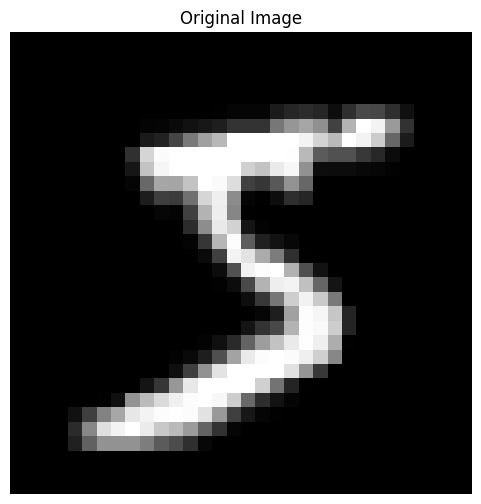

In [ ]:
# Original
plt.figure(figsize=(6, 6))
plt.imshow(img_32, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

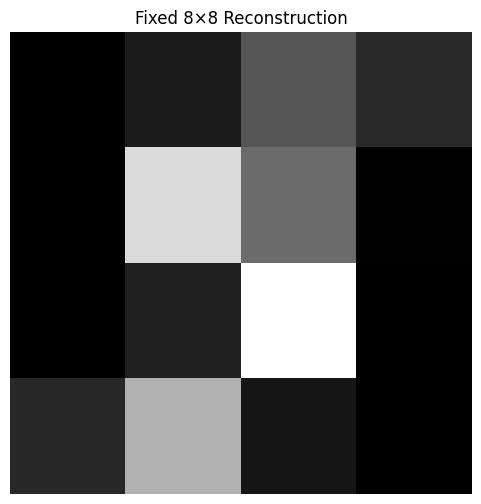

In [ ]:
# Fixed 8x8
plt.figure(figsize=(6, 6))
plt.imshow(fixed_results[8]["reconstructed"], cmap="gray")
plt.title("Fixed 8×8 Reconstruction")
plt.axis("off")
plt.show()

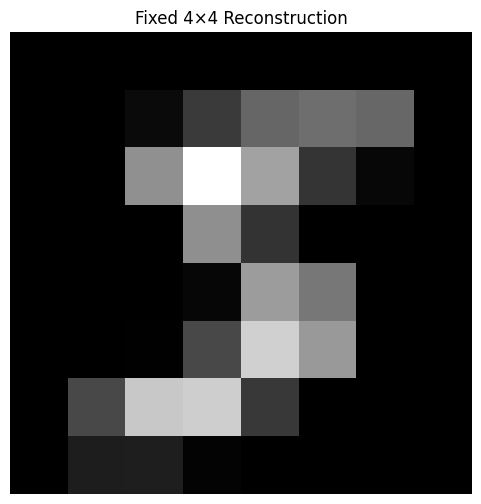

In [ ]:
# Fixed 4x4
plt.figure(figsize=(6, 6))
plt.imshow(fixed_results[4]["reconstructed"], cmap="gray")
plt.title("Fixed 4×4 Reconstruction")
plt.axis("off")
plt.show()

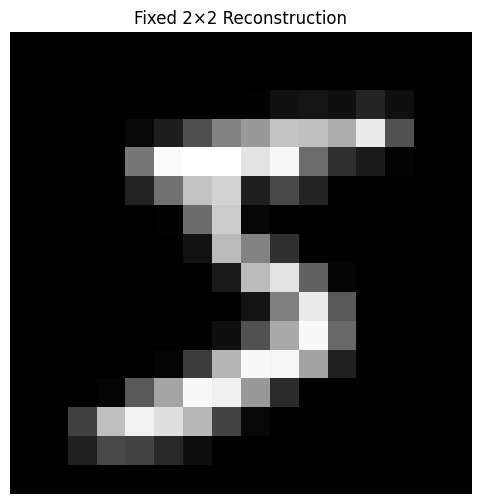

In [ ]:
# Fixed 2x2
plt.figure(figsize=(6, 6))
plt.imshow(fixed_results[2]["reconstructed"], cmap="gray")
plt.title("Fixed 2×2 Reconstruction")
plt.axis("off")
plt.show()

In [ ]:
import pandas as pd
# Final Comparison Table
comparison_data = {
    "Method": [
        "Fixed 8×8",
        "Fixed 4×4",
        "Fixed 2×2",
    ],

    "Patch Size": [
        "8×8",
        "4×4",
        "2×2",
    ],

    "No. of Patches": [
        fixed_results[8]["patches"],
        fixed_results[4]["patches"],
        fixed_results[2]["patches"],
    ],

    "MSE": [
        fixed_results[8]["mse"],
        fixed_results[4]["mse"],
        fixed_results[2]["mse"],
    ],

    "PSNR (dB)": [
        fixed_results[8]["psnr"],
        fixed_results[4]["psnr"],
        fixed_results[2]["psnr"],
    ],

    "SSIM": [
        fixed_results[8]["ssim"],
        fixed_results[4]["ssim"],
        fixed_results[2]["ssim"],
    ]
}

comparison_df = pd.DataFrame(comparison_data)

# Round values for clean display
comparison_df["MSE"] = comparison_df["MSE"].round(2)
comparison_df["PSNR (dB)"] = comparison_df["PSNR (dB)"].round(2)
comparison_df["SSIM"] = comparison_df["SSIM"].round(3)

display(comparison_df)

,Method,Patch Size,No. of Patches,MSE,PSNR (dB),SSIM
0,Fixed 8×8,8×8,16,3680.41,12.47,0.338
1,Fixed 4×4,4×4,64,2230.83,14.65,0.590
2,Fixed 2×2,2×2,256,704.41,19.65,0.859


In [ ]:
# ============================================================
# AVERAGE RESULTS OVER 100 MNIST IMAGES
# ============================================================

NUM_IMAGES = 100

# Store metrics for each patch size
results_100 = {
    8: {"mse": [], "psnr": [], "ssim": []},
    4: {"mse": [], "psnr": [], "ssim": []},
    2: {"mse": [], "psnr": [], "ssim": []}
}

# Process first 100 MNIST images
for idx in range(NUM_IMAGES):

    # Original MNIST image
    image = X_train[idx]

    # Resize 28x28 → 32x32
    image_32 = cv2.resize(
        image,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # Test each fixed patch size
    for size in [8, 4, 2]:

        # Reconstruct image
        reconstructed = reconstruct_fixed(
            image_32,
            size
        )

        # Calculate metrics
        mse, psnr, ssim = calculate_metrics(
            image_32,
            reconstructed
        )

        # Store results
        results_100[size]["mse"].append(mse)
        results_100[size]["psnr"].append(psnr)
        results_100[size]["ssim"].append(ssim)


# ============================================================
# Calculate Average
# ============================================================

average_results = {}

for size in [8, 4, 2]:

    average_results[size] = {
        "patches": (32 // size) ** 2,

        "mse": np.mean(results_100[size]["mse"]),

        "psnr": np.mean(results_100[size]["psnr"]),

        "ssim": np.mean(results_100[size]["ssim"])
    }


# ============================================================
# Display Average Results
# ============================================================

print("=" * 60)
print("AVERAGE RESULTS FOR 100 MNIST IMAGES")
print("=" * 60)

for size in [8, 4, 2]:

    result = average_results[size]

    print(f"\nFixed {size}×{size}")
    print("----------------------------")
    print("Images evaluated :", NUM_IMAGES)
    print("Number of patches:", result["patches"])
    print("Average MSE      :", round(result["mse"], 2))
    print("Average PSNR     :", round(result["psnr"], 2), "dB")
    print("Average SSIM     :", round(result["ssim"], 3))


# ============================================================
# Final Comparison Table
# ============================================================

comparison_100 = pd.DataFrame({

    "Method": [
        "Fixed 8×8",
        "Fixed 4×4",
        "Fixed 2×2"
    ],

    "Patch Size": [
        "8×8",
        "4×4",
        "2×2"
    ],

    "No. of Patches": [
        average_results[8]["patches"],
        average_results[4]["patches"],
        average_results[2]["patches"]
    ],

    "Average MSE": [
        average_results[8]["mse"],
        average_results[4]["mse"],
        average_results[2]["mse"]
    ],

    "Average PSNR (dB)": [
        average_results[8]["psnr"],
        average_results[4]["psnr"],
        average_results[2]["psnr"]
    ],

    "Average SSIM": [
        average_results[8]["ssim"],
        average_results[4]["ssim"],
        average_results[2]["ssim"]
    ]
})

# Round values
comparison_100["Average MSE"] = comparison_100["Average MSE"].round(2)
comparison_100["Average PSNR (dB)"] = comparison_100["Average PSNR (dB)"].round(2)
comparison_100["Average SSIM"] = comparison_100["Average SSIM"].round(3)

display(comparison_100)

AVERAGE RESULTS FOR 100 MNIST IMAGES

Fixed 8×8
----------------------------
Images evaluated : 100
Number of patches: 16
Average MSE      : 3334.85
Average PSNR     : 13.09 dB
Average SSIM     : 0.309

Fixed 4×4
----------------------------
Images evaluated : 100
Number of patches: 64
Average MSE      : 1848.68
Average PSNR     : 15.59 dB
Average SSIM     : 0.613

Fixed 2×2
----------------------------
Images evaluated : 100
Number of patches: 256
Average MSE      : 611.72
Average PSNR     : 20.4 dB
Average SSIM     : 0.872


,Method,Patch Size,No. of Patches,Average MSE,Average PSNR (dB),Average SSIM
0,Fixed 8×8,8×8,16,3334.85,13.09,0.309
1,Fixed 4×4,4×4,64,1848.68,15.59,0.613
2,Fixed 2×2,2×2,256,611.72,20.40,0.872
